

<div style="max-width: 850px;">

# **LLM - The Transformer lifecycle**

---

This project is used to understand the lifecycle of transformers 
From data cleaning to speed up inference
We will keep it small such that we can train several transformers
All will be implemented from scratch
Later we can upgrade to use everything using hugging face interfaces


**Requirements**

These are requirements and how to install them in your environment

* `pip install datasets`

</div>



<div style="max-width: 850px;">

# The dataset

---

## Data curation and preparation

---

We will start small, using `tiny stories` dataset.
This dataset lives in huggingface. 

We will observe it's distribution and compute useful statistics from the dataset.

To process text we should also use a tokenizer. At the moment we are not interested in training one ourselves and we will use the `GPT2TokenizerFast` available in Huggingface. `GPT2TokenizeFast` implements a BPE (byte-pair encoding) tokenization.

</div>


In [2]:
%load_ext autoreload
%autoreload 2

import matplotlib.pyplot as plt
import tqdm
import logging

import sys
from pathlib import Path

import numpy as np
from wordcloud import WordCloud


from transformers import GPT2TokenizerFast
import pandas as pd
from datasets import load_from_disk
from IPython.display import display


# imports from transformers lyfecycle

# Support kernels launched from the project root or notebooks directory.
project_root = Path.cwd().resolve()
if not (project_root / 'src' / 'data_cycle.py').is_file():
    project_root = project_root.parent
if not (project_root / 'src' / 'data_cycle.py').is_file():
    raise FileNotFoundError('Run this notebook from the project root or notebooks directory')
sys.path.insert(0, str(project_root / 'src'))

import data_cycle


logging.basicConfig(level=logging.INFO)
logging.getLogger('httpx').setLevel(logging.ERROR)
logging.getLogger('httpcore').setLevel(logging.ERROR) 
_LOGGER = logging.getLogger(__name__)

data_path = project_root / 'datasets'
# artifacts_path = project_root / 'artifacts' / 'dataset_cycle'
artifacts_path = Path('/home/angel/src/transformers_lifecycle/artifacts/dataset_cycle')

# Run all saved-artifact stages from a terminal:
# python scripts/run_dataset_pipeline.py --config configs/dataset_cycle.json
# For a custom output folder, set artifacts_path above to that folder.
import json
pipeline_config_path = artifacts_path / 'pipeline_config.json'
pipeline_config = (
    json.loads(pipeline_config_path.read_text(encoding='utf-8'))
    if pipeline_config_path.is_file() else {}
)
saved_minhash_settings = pipeline_config.get('minhash', {})

# Experiment configuration and reusable processors.
train_source = data_cycle.TINYSTORIES_TRAIN_SOURCE
valid_source = data_cycle.TINYSTORIES_VALIDATION_SOURCE
code_source = data_cycle.PYTHON_CODE_TRAIN_SOURCE

num_proc = pipeline_config.get('num_proc', 7)
preprocess_batch_size = pipeline_config.get('batch_size', 1000)
tokenization_batch_size = 512
signature_batch_size = pipeline_config.get('signature_batch_size', 256)

normalization_config = data_cycle.NormalizationConfig(
    max_new_lines=pipeline_config.get('normalization', {}).get('max_new_lines', 3),
)
token_display_config = data_cycle.DEFAULT_TOKEN_DISPLAY_CONFIG

train_normalizer = data_cycle.TextNormalizer(
    transformations=data_cycle.PROSE_NORMALIZATION,
    config=normalization_config,
    text_column=train_source.text_column,
)
valid_normalizer = data_cycle.TextNormalizer(
    transformations=data_cycle.PROSE_NORMALIZATION,
    config=normalization_config,
    text_column=valid_source.text_column,
)

print('Done!')

The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload
Done!


In [4]:
# Check only the artifacts required for inspection through exact deduplication.
required_artifacts = [
    'normalized_train', 'normalized_validation', 'cleaning_metrics.csv',
    'diagnosis/document_lengths.csv', 'diagnosis/token_frequencies.csv',
    'diagnosis/diagnosis_summary.json', 'exact_dedup_train',
    'exact_dedup_validation', 'exact_dedup_metrics.csv', 'exact_duplicate_pairs.csv',
]
artifact_status = pd.DataFrame({
    'Artifact': required_artifacts,
    'Available': [(artifacts_path / name).exists() for name in required_artifacts],
})
display(artifact_status)
missing_artifacts = artifact_status.loc[~artifact_status['Available'], 'Artifact'].tolist()
#if missing_artifacts:
#    raise FileNotFoundError('Missing saved artifacts: ' + ', '.join(missing_artifacts))


,Artifact,Available
0,normalized_train,True
1,normalized_validation,True
2,cleaning_metrics.csv,True
3,diagnosis/document_lengths.csv,False
4,diagnosis/token_frequencies.csv,False
5,diagnosis/diagnosis_summary.json,False
6,exact_dedup_train,True
7,exact_dedup_validation,True
8,exact_dedup_metrics.csv,True
9,exact_duplicate_pairs.csv,True


In [5]:
# Load saved normalized, nonempty stories; no raw-dataset download is needed.
stories_train_dataset = load_from_disk(str(artifacts_path / 'normalized_train'))
stories_valid_dataset = load_from_disk(str(artifacts_path / 'normalized_validation'))


In [4]:
# Preview normalized training documents (these are not the raw source texts).
_LOGGER.info('Previewing normalized training documents after empty removal')
data_cycle.display_dataset_information(stories_train_dataset)
display(stories_train_dataset.select(range(min(10, len(stories_train_dataset)))).to_pandas())


INFO:__main__:Previewing normalized training documents after empty removal
INFO:diagnostics:Columns (1): ['text']
INFO:diagnostics:Rows: 2119489
INFO:diagnostics:Features: {'text': Value('string')}
INFO:diagnostics:Split: None
INFO:diagnostics:Cache files: [{'filename': '/Users/angelmartinez/src/transformers_lifecycle/artifacts/dataset_cycle/normalized_train/data-00000-of-00004.arrow'}, {'filename': '/Users/angelmartinez/src/transformers_lifecycle/artifacts/dataset_cycle/normalized_train/data-00001-of-00004.arrow'}, {'filename': '/Users/angelmartinez/src/transformers_lifecycle/artifacts/dataset_cycle/normalized_train/data-00002-of-00004.arrow'}, {'filename': '/Users/angelmartinez/src/transformers_lifecycle/artifacts/dataset_cycle/normalized_train/data-00003-of-00004.arrow'}]
INFO:diagnostics:Sample 1: {'text': 'One day, a little girl named Lily found a needle in her room. She knew it was difficult to play with it because it was sharp. Lily wanted to share the needle with her mom, so sh

,text
0,"One day, a little girl named Lily found a need..."
1,"Once upon a time, there was a little car named..."
2,"One day, a little fish named Fin was swimming ..."
3,"Once upon a time, in a land full of trees, the..."
4,"Once upon a time, there was a little girl name..."
5,"Once upon a time, in a big lake, there was a b..."
6,"Once upon a time, in a small town, there was a..."
7,"Once upon a time, in a peaceful town, there li..."
8,"Once upon a time, there was a clever little do..."
9,"One day, a fast driver named Tim went for a ri..."



<div style="max-width: 850px;">

## Dataset diagnosis
---

We run data diagnosis by computing and observing dataset statistics. These will help us to decide what pre-processing steps we need to apply to clean, standrize and filter documents. 

Usually this step is performed on a tokenized dataset. We will keep it simple and use `GPT2TokenizerFast`, which is a tokenizer trained using the BytePairing algorithm, and compute the following:

   - **Number of documents**: a document can be simply put as the basic unit in the dataset. This is a story within `tiny stories` dataset.
   - **Document length distribution**: the distribution help us identify documents that are too short or too long. 
   - **Vocabulary/Token distribution**: we will plot Zipf plots. These help us to identify if there are tokens that are too often repeating - such as html tags - and can indicate garbage or spurious dataset. For more context on these plots look [at this article.](https://www.nngroup.com/articles/zipf-curves-and-website-popularity/#:~:text=According%20to%20much%20available%20data%2C%20web%20use,number%20of%20elements%20that%20score%20very%20low)

**Diagnosis runs separately:** run `python scripts/run_dataset_diagnosis.py` from the project root, then load its artifacts below. No tokenized dataset is saved. Diagnosis counts full token sequences without truncation; GPT-2 training sequences are limited separately.

</div>



In [ ]:
# Run once in a terminal from the project root:
# python scripts/run_dataset_diagnosis.py
# Re-run the script when the raw dataset or diagnosis tokenizer changes.
import json
import pandas as pd

diagnosis_path = artifacts_path / 'diagnosis'
required_files = ['document_lengths.csv', 'token_frequencies.csv', 'diagnosis_summary.json']
if any(not (diagnosis_path / name).is_file() for name in required_files):
    raise FileNotFoundError(
        'Missing diagnosis artifacts. Run: python scripts/run_dataset_diagnosis.py'
    )

document_lengths = pd.read_csv(diagnosis_path / 'document_lengths.csv')
token_frequencies = pd.read_csv(
    diagnosis_path / 'token_frequencies.csv', keep_default_na=False,
)
diagnosis_summary = json.loads((diagnosis_path / 'diagnosis_summary.json').read_text())
sequence_lengths = document_lengths['token_count'].to_numpy()

# Use the GPT-2 tokenizer cached by the diagnosis script; no network lookup is needed.
# This tokenizer is also used later for the final cleaned-data tokenization.
tokenizer = GPT2TokenizerFast.from_pretrained('gpt2', local_files_only=True)


In [6]:
vocabulary = tokenizer.get_vocab()
_LOGGER.info('Len of vocabulary: %d', len(vocabulary))
_LOGGER.info('Loaded diagnosis for %d documents', diagnosis_summary['document_count'])


INFO:__main__:Len of vocabulary: 50257
INFO:__main__:Loaded diagnosis for 2119719 documents


In [7]:
# Reconstruct the inputs used by the existing plots from saved counts.
id_dist = dict(zip(token_frequencies['token_id'], token_frequencies['count']))
id_dist_list = sorted(id_dist.items())


In [8]:
# Looking to some parts of the dataset

# Let's look at the largest ocurrence. We will find that there is only a few
# tokens that are taking a lot of the counts -> over 10M occurences!
topk = 10
id_dist__ = sorted([(k, v) for (k, v) in id_dist_list], key=lambda x: x[1])

_LOGGER.info(f' The following are the {topk} tokens with largest ocurrence')
vocab_reversed = {v:k for k, v in vocabulary.items()}

for k, v in [[vocab_reversed[x[0]], x[1]] for x in id_dist__[-topk:]]:
    _LOGGER.info(f' {k} -> {v}')


INFO:__main__: The following are the 10 tokens with largest ocurrence
INFO:__main__: Ġher -> 4523829
INFO:__main__: Ġit -> 5185957
INFO:__main__: Ġwas -> 9437796
INFO:__main__: Ġa -> 11368431
INFO:__main__: Ġto -> 12634330
INFO:__main__: Ġthe -> 16600383
INFO:__main__: , -> 16631454
INFO:__main__: Ġand -> 17810413
INFO:__main__: Ċ -> 18424730
INFO:__main__: . -> 34651025


In [9]:
# plot counts and world cloud of tokens


mean, median, std = (diagnosis_summary[key] for key in ('mean', 'median', 'std'))

_LOGGER.info('Total of documents in the dataset: %d', diagnosis_summary['document_count'])
_LOGGER.info(f' Document length statistics: mean:{mean}; median: {median}; std: {std}')
_LOGGER.info(f' Vocabulary size of tokenizer: {len(vocabulary)}')




INFO:__main__:Total of documents in the dataset: 2119719
INFO:__main__: Document length statistics: mean:222.61088238582568; median: 191; std: 107.08757064377541
INFO:__main__: Vocabulary size of tokenizer: 50257


Text(0.5, 1.0, 'Token Frequency (no-punct)')

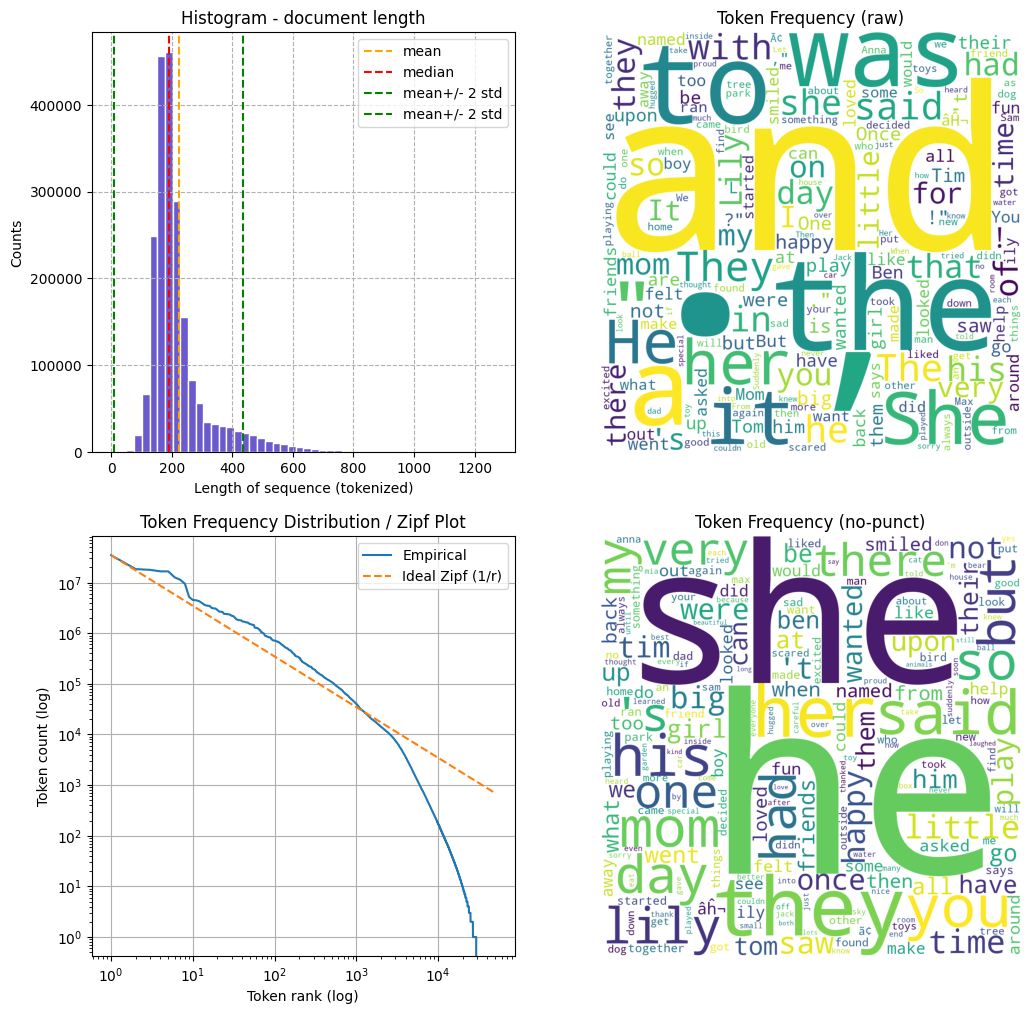

In [10]:
fig, axes = plt.subplots(2, 2, figsize=(12, 12))

axes[0,0].hist(sequence_lengths, bins=50, color='slateblue', edgecolor='white')
axes[0,0].axvline(x=mean, linestyle='--', color='orange', label='mean')
axes[0,0].axvline(x=median, linestyle='--', color='red', label='median')

axes[0,0].axvline(x=mean+2*std, linestyle='--', color='green', label='mean+/- 2 std')
axes[0,0].axvline(x=mean-2*std, linestyle='--', color='green', label='mean+/- 2 std')

axes[0,0].legend()
axes[0,0].set_xlabel("Length of sequence (tokenized)")
axes[0,0].set_title('Histogram - document length')
axes[0,0].set_ylabel('Counts')
axes[0,0].grid(True, linestyle='--')

token_counts = data_cycle.ids_to_token_counts(id_dist, tokenizer, config=token_display_config)
max_words = 200

wc = WordCloud(
    width=1000,
    height=1000,
    background_color="white",
    max_words=max_words
)

wc.generate_from_frequencies(token_counts)
axes[0,1].imshow(wc)
axes[0,1].axis("off")
axes[0,1].set_title("Token Frequency (raw)")

counts = np.array(sorted(id_dist.values(), reverse=True))
ranks = np.arange(1, len(counts) + 1)
# ideal Zipf curve (scaled to match first point)
ideal = counts[0] / ranks

axes[1,0].loglog(ranks, counts, label='Empirical')
axes[1,0].loglog(ranks, ideal, linestyle="--", label="Ideal Zipf (1/r)")
axes[1,0].set_xlabel("Token rank (log)")
axes[1,0].set_ylabel("Token count (log)")
axes[1,0].set_title("Token Frequency Distribution / Zipf Plot")
axes[1,0].grid(True)
axes[1,0].legend()


display_counts = data_cycle.filter_token_counts_for_display(id_dist, tokenizer, config=token_display_config)
wc.generate_from_frequencies(display_counts)
axes[1,1].imshow(wc)
axes[1,1].axis("off")
axes[1,1].set_title("Token Frequency (no-punct)")



In [11]:
# Observing the most and least ranked tokens
N = 10  # configurable

# Sort (token_id, count) by frequency
ranked_tokens = sorted(
    id_dist.items(),
    key=lambda x: x[1],
    reverse=True
)

def show_token(tokenizer, token_id):
    # Raw GPT-2 token representation + decoded human-readable text
    raw = tokenizer.convert_ids_to_tokens(token_id)
    decoded = tokenizer.decode([token_id])
    return raw, decoded


print(f"Top {N} highest-ranked tokens:")
for rank, (token_id, count) in enumerate(ranked_tokens[:N], start=1):
    raw, decoded = show_token(tokenizer, token_id)
    print(
        f"Rank {rank:>6} | "
        f"ID {token_id:>6} | "
        f"token={repr(raw):<18} | "
        f"text={repr(decoded):<18} | "
        f"count={count}"
    )

print(f"\nBottom {N} lowest-ranked tokens:")
total = len(ranked_tokens)

for rank, (token_id, count) in enumerate(
    ranked_tokens[-N:],
    start=total - N + 1
):
    raw, decoded = show_token(tokenizer, token_id)
    print(
        f"Rank {rank:>6} | "
        f"ID {token_id:>6} | "
        f"token={repr(raw):<18} | "
        f"text={repr(decoded):<18} | "
        f"count={count}"
    )

Top 10 highest-ranked tokens:
Rank      1 | ID     13 | token='.'                | text='.'                | count=34651025
Rank      2 | ID    198 | token='Ċ'                | text='\n'               | count=18424730
Rank      3 | ID    290 | token='Ġand'             | text=' and'             | count=17810413
Rank      4 | ID     11 | token=','                | text=','                | count=16631454
Rank      5 | ID    262 | token='Ġthe'             | text=' the'             | count=16600383
Rank      6 | ID    284 | token='Ġto'              | text=' to'              | count=12634330
Rank      7 | ID    257 | token='Ġa'               | text=' a'               | count=11368431
Rank      8 | ID    373 | token='Ġwas'             | text=' was'             | count=9437796
Rank      9 | ID    340 | token='Ġit'              | text=' it'              | count=5185957
Rank     10 | ID    607 | token='Ġher'             | text=' her'             | count=4523829

Bottom 10 lowest-ranked tokens:



<div style="max-width: 850px;">

**Diagnosis**


* **Most frequent tokens**. These are punctuation tokens and lots of short length words. For training, keep punctuation and frequent tokens - **removing them breaks language modeling because the model must learn *syntax, spacing, sentence boundaries, formatting, etc.***. **It only becomes a problem** if the top tokens are things like `<, >, +, http, www, etc` or repeated boilerplate tokens from HTML, templates, logs, menus, tables, or corrupted text.

    * **Conclusion**. There are no unwanted tokens in this dataset. When removed punctuation and `articles` such as "the", "that" etc, most frequent tokens become pronouns like "he", "she" - which is normal in stories.


* **Length of documents have long tails**. We don't want documents on both tails - very short documents and very long documents. The length of the documents do not make them "be of bad quality", but it's more of a question of efficient training. For example, very short documents make training inefficient because **the model sees little context**. Short examples often include: titles, menu labels, broken web fragments, captions, etc. Very long documents will simply be cut by a `MAX_SEQUENCE_LENGTH` - loading them into memory will be inefficient. In practice document length will be kept in boundaries `MIN_SEQUENCE_LENGTH` and `MAX_SEQUENCE_LENGTH` with boundaries depending on the dataset.

    * **Conclusion**. There is a long tail for long documents, but overall the distribution looks good. During our exercise we will keep the length of ducuent short with `MIN_SEQUENCE_LENGTH=128` and `MAX_SEQUENCE_LENGTH=512`.


* **Zipf curves**. Zipf curves help us visualizaing the distributions of the tokens in the dataset by ranking: most frequent token has rank 1. This plot should be looking smooth and decreasing and spikes and clifts on the tail. We can diagnose the curve by visualizaing the ideal Zipf distribution `1/rank`.

    * **Conclusion**. The token-frequency distribution approximately follows a Zipf-like distribution, with token frequency decreasing roughly as a power law with rank. The highest-frequency tokens include punctuation, whitespace-related tokens, and common lexical/subword tokens, which explains the relatively flat head of the distribution. The middle portion of the distribution follows the 1/rank reference reasonably well. At high ranks, the empirical distribution falls below the ideal Zipf curve, forming a long tail of rare tokens. Inspection of these tokens shows meaningful low-frequency terms such as "Bigfoot" and "Iodine", suggesting that the tail contains legitimate story-specific vocabulary rather than simply noise. Therefore, rare tokens should not be removed solely based on their frequency.


</div>



<div style="max-width: 850px;">

## Pre-processing and data curation
---

**Data curation is the first and upmost component on quality control on LLMs**. Curation is performed as an iterative process where apply filters, models and heuristics to improve the overall quality. Common pre-processing steps are removing exact duplicates, removing semantic similar elements, and filter elements based on "explainability". Each step in the data curation cycle contributes in different ways to efficient learning of LLMs. 

Data curation follows a simple recipe:

1. **Normalise text**: unicode conversion, boilerplate, stripping, etc,
2. **Remove empty documents**: filter empty or whitespace-only text after normalization,
3. **Exact deduplication**: using hasing,
4. **Near deduplication**: using minhash and local sensitive hashing (LSH),
5. **Apply tokenization**, we can use the same BPE tokenizer,
6. **Filter by token length**: after tokenization we remove elements outside of `MIN_SEQUENCE_LENGTH` and `MAX_SEQUENCE_LENGTH`,
7. **Perplexity filtering**: using document "explainability" from a LLM as a meassure of the quality (can be a strong or a small LLM),
8. **[optional] Semantic deduplication**: converting documents to embeddings and using nearest neigbours,
9. **Iteratively curate** dataset by training and analysing outputs.


In the following we will implement each of these steps in our dataset.

</div>




<div style="max-width: 850px;">

### Step 1 - Normalizing text

---

In the normalization step we simply convert all the text to unicode, strip and remove more than 1 spaces. Specifically, we will focus in the following normalization

1. **Unicode normalization**. Normalize different unicode representations into a canonical form: curly quotes → standard quotes, accented characters → consistent encoding,
2. **Whitespace normalization**. Collapse multiple spaces, normalize tabs/newlines, strip leading/trailing spaces,
3. **Line break normalization**. Convert `\r\n`, `\r → \n` and collapse excessive newlines (e.g., >2 → 2),
4. **Control character removal**. Remove: non-printable characters, zero-width spaces and Unicode artifacts,
5. **Standardize quotes and punctuation**. “ ” → ", ‘ ’ → ', normalize dashes (— → -),
6. **Lowercasing reduces vocabulary entropy, but removes signal (e.g., named entities)** so it's better to keep casing.

Run `python scripts/run_dataset_preparation.py` from the project root to normalize training and validation data and remove empty documents. The following cells load the saved datasets and cleaning metrics; no normalization is repeated in the notebook.


</div>


In [ ]:
# Normalized datasets were loaded above for previews and remain unchanged.
# Load the saved cleaning metrics; do not rerun normalization or filtering.
cleaning_metrics = pd.read_csv(artifacts_path / 'cleaning_metrics.csv')


In [13]:
display(cleaning_metrics)
for row in cleaning_metrics.itertuples(index=False):
    _LOGGER.info(
        '%s: %d documents after normalization; %d after empty removal (%.2f%% removed)',
        row.split, row.after_normalization, row.after_empty_removal, row.removed_percentage,
    )


,split,input_count,after_normalization,after_empty_removal,removed_count,removed_percentage
0,Training,2119719,2119719,2119489,230,0.01085
1,Validation,21990,21990,21990,0,0.00000


INFO:__main__:Training: 2119719 documents after normalization; 2119489 after empty removal (0.01% removed)
INFO:__main__:Validation: 21990 documents after normalization; 21990 after empty removal (0.00% removed)


In [14]:
# Continue with saved exact-deduplication results below.
# To inspect normalization interactively on a small example:
# train_normalizer.normalize_text('  A story.  ')



<div style="max-width: 850px;">


### Step 2 -Exact deduplication with hashing

---

We will use a hash to remove exact duplicates. First, we will convert all the text to a hash - after normalization - using `hashlib.sha256`. This will create a set of hashes whifh to perform deduplication and make fast lookups.

</div>

Run `python scripts/run_exact_deduplication.py` to hash and deduplicate the saved normalized datasets. Load the results below to plot removal percentages and inspect duplicate pairs.


In [ ]:
# Run once from the project root:
# python scripts/run_exact_deduplication.py
# Use --overwrite to regenerate exact-deduplication outputs.
from datasets import load_from_disk
import pandas as pd

exact_files = [
    'exact_dedup_train', 'exact_dedup_validation',
    'exact_dedup_metrics.csv', 'exact_duplicate_pairs.csv',
]
if any(not (artifacts_path / name).exists() for name in exact_files):
    raise FileNotFoundError(
        'Missing exact-deduplication artifacts. Run: python scripts/run_exact_deduplication.py'
    )

# Pair indices reference this saved dataset before duplicate removal.
stories_train_dataset_cpy = load_from_disk(str(artifacts_path / 'normalized_train'))
stories_train_dataset = load_from_disk(str(artifacts_path / 'exact_dedup_train'))
stories_valid_dataset = load_from_disk(str(artifacts_path / 'exact_dedup_validation'))


In [ ]:
exact_dedup_metrics = pd.read_csv(artifacts_path / 'exact_dedup_metrics.csv')
exact_dedup_removed = dict(zip(
    exact_dedup_metrics['split'], exact_dedup_metrics['removed_percentage'],
))
for row in exact_dedup_metrics.itertuples(index=False):
    _LOGGER.info(
        '%s: Removed %d exact duplicates (%.2f%%) -> %d vs %d',
        row.split, row.removed_count, row.removed_percentage, row.after, row.before,
    )


In [ ]:
# Inspect saved training pairs; no hashing or duplicate detection is repeated.
X = 10
if not isinstance(X, int) or isinstance(X, bool) or X < 0:
    raise ValueError('X must be a non-negative integer')

# Stream the CSV so a small preview does not load every duplicate pair.
import csv
from itertools import islice

with (artifacts_path / 'exact_duplicate_pairs.csv').open(newline='', encoding='utf-8') as handle:
    training_pairs = (
        (int(row['original_index']), int(row['duplicate_index']))
        for row in csv.DictReader(handle) if row['split'] == 'Training'
    )
    exact_duplicate_examples = list(islice(training_pairs, X))



In [20]:
exact_duplicate_table = data_cycle.display_duplicate_pairs(
    stories_train_dataset_cpy, exact_duplicate_examples,
    text_column=train_source.text_column, max_pairs=X,
)

# For export, call the same method with output='markdown' or output='html'.


Original index,Duplicate index,Original text,Duplicate text
7100,39241,"Once upon a time, there was a little duck named Ducky. Ducky was very sad because he didn't have any friends to play with. One day, Ducky met a friendly frog named Froggy. ""Hi, Froggy! Will you be my friend?"" asked Ducky. ""Of course, I will be your friend, Ducky!"" replied Froggy. Froggy provided Ducky with a yellow flower to make him feel better. Ducky was so happy and thanked Froggy. They played together all day and had so much fun. When it was time to go home, Ducky said, ""Froggy, you are such a good friend. I am glad we met today."" Froggy smiled and said, ""You are my friend too, Ducky. Let's play again tomorrow!"" The sky turned gray, and Ducky went back to his nest feeling happy because he finally found a friend.","Once upon a time, there was a little duck named Ducky. Ducky was very sad because he didn't have any friends to play with. One day, Ducky met a friendly frog named Froggy. ""Hi, Froggy! Will you be my friend?"" asked Ducky. ""Of course, I will be your friend, Ducky!"" replied Froggy. Froggy provided Ducky with a yellow flower to make him feel better. Ducky was so happy and thanked Froggy. They played together all day and had so much fun. When it was time to go home, Ducky said, ""Froggy, you are such a good friend. I am glad we met today."" Froggy smiled and said, ""You are my friend too, Ducky. Let's play again tomorrow!"" The sky turned gray, and Ducky went back to his nest feeling happy because he finally found a friend."
7101,39242,"Once upon a time, there was a little boy named Timmy. Timmy loved going to the store with his mom. One day, he saw a toy that he really wanted. He asked his mom, ""Mommy, can I please have this toy?"" His mom looked at the price and said it was too expensive. Timmy was sad but understood. As they were walking around the store, Timmy saw something unusual. It was a big, pink elephant stuffed animal. He had never seen anything like it before. He asked his mom, ""Mommy, what is that unusual thing?"" His mom smiled and said it was a stuffed animal. Timmy thought it was silly but he still wanted the toy he saw earlier. When they got to the checkout, Timmy saw the toy he wanted again. He asked his mom, ""Mommy, can we please buy the toy now?"" His mom looked at the price again and said it was still too expensive. Timmy was disappointed but he knew there would be other toys he could ask for next time.","Once upon a time, there was a little boy named Timmy. Timmy loved going to the store with his mom. One day, he saw a toy that he really wanted. He asked his mom, ""Mommy, can I please have this toy?"" His mom looked at the price and said it was too expensive. Timmy was sad but understood. As they were walking around the store, Timmy saw something unusual. It was a big, pink elephant stuffed animal. He had never seen anything like it before. He asked his mom, ""Mommy, what is that unusual thing?"" His mom smiled and said it was a stuffed animal. Timmy thought it was silly but he still wanted the toy he saw earlier. When they got to the checkout, Timmy saw the toy he wanted again. He asked his mom, ""Mommy, can we please buy the toy now?"" His mom looked at the price again and said it was still too expensive. Timmy was disappointed but he knew there would be other toys he could ask for next time."
7102,39243,"Once upon a time, there was a brave giraffe named Gigi. She loved to run and play with her friends in the jungle. One day, while playing hide and seek, she got her neck stuck in a tree branch. She cried for help, but no one could hear her. Days went by, and Gigi's neck started to hurt. She couldn't move or eat. Her friends searched everywhere for her, but they couldn't find her. Finally, a wise old owl found Gigi and called for help. A group of animals came to rescue Gigi. They worked together to restore her neck and get her free from the branch. Gigi was so happy to be reunited with her friends and able to

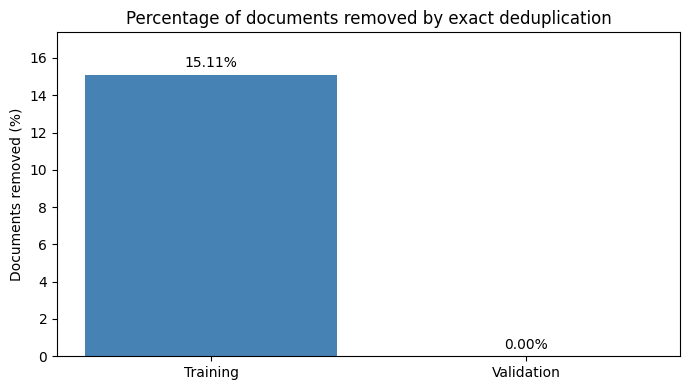

In [21]:
fig, ax = plt.subplots(figsize=(7, 4))
bars = ax.bar(
    list(exact_dedup_removed),
    list(exact_dedup_removed.values()),
    color=['steelblue', 'darkorange'],
)
ax.bar_label(bars, labels=[f'{percentage:.2f}%' for percentage in exact_dedup_removed.values()], padding=3)
ax.set_title('Percentage of documents removed by exact deduplication')
ax.set_ylabel('Documents removed (%)')
ax.ticklabel_format(axis='y', style='plain')
ax.set_ylim(0, max(max(exact_dedup_removed.values()) * 1.15, 1))
fig.tight_layout()
plt.show()



<div style="max-width: 850px;">


### Step 3 - Near deduplication

---

Finding near duplicates help us to remove documents in the dataset that are not exact duplicates based on text, but instead have similar structure and content. We can define that two documents are near duplicates if they contain similar local patterns in their `n-grams` that are usually constructed in word level. 

N-grams have the following properties:

1. Preserve local structure,
2. Are robust to small details,
3. Ignore global ordering,
4. Are sensitive to similar/copied structure.

Using the N-grams of two documents, the similarity becomes comparing how much overlap have the two sets:

$$
J(A,B) = \frac{|A\cap B|}{|A\cup B|}.
$$

The above is the *Jaccard similarity*. However, at scale this becomes infeasible given that the complexity is $O(N^2)$, $N$ equal to the length of both sets. The solution is to use **MinHashing**. MinHashing converts the documents to a signature and allows us to compute the above expression with the property:

$$
P(\text{MinHash}(A)=\text{MinHash}(B)) = J(A,B).
$$

**The intuition** behind is that, for a permutation of an n-gram that is in $A\cup B$ it must be in: 1) in $A\cap B$, or 2) must be in A or B. The probability that lies in the intersection is $\frac{|A\cap B|}{|A\cup B|}$.

To implement **MinHashing** we simulate permutations with hash functions $h_i$ to create a document signature:

$$
m_i = h_i(g), g\in A.
$$

Then

$$
\text{signature}(A) = [m_1, m_2, m_3, ..., m_K],
$$

for $k=K$ hash functions. Then we compare two documents by computing:

$$
\hat{J}(A, B) = \frac{1}{K} \sum_{i=1}^K I[m_i(A)=m_i(B)].
$$

However, this computation is still $O(N^2)$. To speed up computation we turn our eyes to LSH (local sensitive hashing) to **help us to only compute the expensive comparison metric on documents that are similar in some bands**. Specifically, LSH performs the following steps:

1. Split each MinHash signature into $b$ bands, each containing $r$ rows:

$$
n = b\cdot r,
$$

where \(n\) is the signature length.

2. Hash each band independently into a hash table/bucket.

3. Define candidate pairs: two documents $A,B$ become a candidate pair if their signatures are identical in all $r$ rows of at least one band.

4 Only for these candidate pairs, compute a more precise similarity measure, such as $\hat{J}(A, B)$.


For example, for a two component band, a signature can become:
   
$$
\text{signature}(A) = [[m_1, m_2], [m_3, m_4], ..., [m_{K-1}, m_K]].
$$

Luckily, there are packages in Python that can help us computing these permutations - MinHashes and similarities with LSH. In this exercise we will use `datasketch`. In practice, we need to tune the following parameters:

- **`NGRAM size` — controls the representation.** We split each document into overlapping $n$-grams before computing MinHash. Smaller $n$-grams create more overlap between documents and are more tolerant of small textual changes, but can make unrelated documents appear similar. Larger $n$-grams capture more specific context and reduce accidental matches, but become more sensitive to small edits. **Trade-off:** smaller $n$ → higher recall / lower precision; larger $n$ → higher precision / lower recall.

- **`Number of permutations` — controls the accuracy of MinHash.** This determines the number of hash functions used to construct each MinHash signature. More permutations give a more accurate estimate of the true Jaccard similarity and reduce the variance of $\hat J(A,B)$, but increase hashing cost, memory usage, and LSH index size. **Trade-off:** more permutations → better similarity estimates but more compute and memory; fewer → faster and cheaper but noisier estimates.

- **`Similitud threshold` — controls which similarities LSH targets.** This tells LSH approximately where we want the transition between unlikely and likely candidate pairs to occur. A higher threshold retrieves fewer, more strongly similar candidates but risks missing useful moderately similar pairs. A lower threshold generates more candidates, improving recall but increasing false positives and downstream comparisons. **Trade-off:** higher threshold → higher precision / lower recall; lower threshold → higher recall / lower precision.

- **\(b\) and \(r\) — control the LSH banding behavior.** The MinHash signature is divided into \(b\) bands containing $r$ rows each, roughly satisfying $br=\text{NUM\_PERM}$. Two documents become candidates when they match on all \(r\) rows of at least one band. More bands with fewer rows make LSH more permissive; fewer bands with more rows make it stricter. **Trade-off:** more bands → higher recall / more false positives; more rows per band → higher precision / more false negatives.


</div>


In [ ]:
# Experiments run in separate scripts; the notebook loads their saved results.
train_experiment_dataset = stories_train_dataset


### Compare saved n-gram experiments

Load both experiments below without rerunning deduplication. Compare retrieved LSH candidates and removed documents against the training exact-deduplication baseline, then preview removed documents using saved retained indices.


In [6]:
# Load both saved experiments; paths are relative to artifacts_path.
ngram_result_dirs = {
    'With exact duplicates': artifacts_path / 'normalized_train_ngram_experiment',
    'Without exact duplicates': artifacts_path / 'experiment_exact_and_minhash' / 'results',
}
ngram_results_table = pd.concat([
    pd.read_csv(directory / 'ngram_results.csv').assign(dataset=label)
    for label, directory in ngram_result_dirs.items()
], ignore_index=True).sort_values(['dataset', 'ngram_size'])
# Candidate counts parsed from the experiment logs supplied for this comparison.
import json
candidate_counts_path = artifacts_path / 'minhash_candidate_counts.json'
candidate_counts = json.loads(candidate_counts_path.read_text(encoding='utf-8'))
ngram_results_table['candidate_total'] = [
    candidate_counts[row.dataset][str(row.ngram_size)]
    for row in ngram_results_table.itertuples(index=False)
]
exact_training_removed = int(
    pd.read_csv(artifacts_path / 'exact_dedup_metrics.csv')
    .set_index('split').loc['Training', 'removed_count']
)
display(ngram_results_table[[
    'dataset', 'ngram_size', 'total_documents', 'candidate_total',
    'removed_count', 'removed_percentage',
]])


,dataset,ngram_size,total_documents,candidate_total,removed_count,removed_percentage
0,With exact duplicates,2,2119489,423332,320241,15.109349
1,With exact duplicates,3,2119489,320668,320241,15.109349
2,With exact duplicates,4,2119489,320267,320241,15.109349
3,With exact duplicates,5,2119489,320245,320241,15.109349
4,Without exact duplicates,2,1799248,86389,0,0.000000
5,Without exact duplicates,3,1799248,368,0,0.000000
6,Without exact duplicates,4,1799248,24,0,0.000000
7,Without exact duplicates,5,1799248,4,0,0.000000


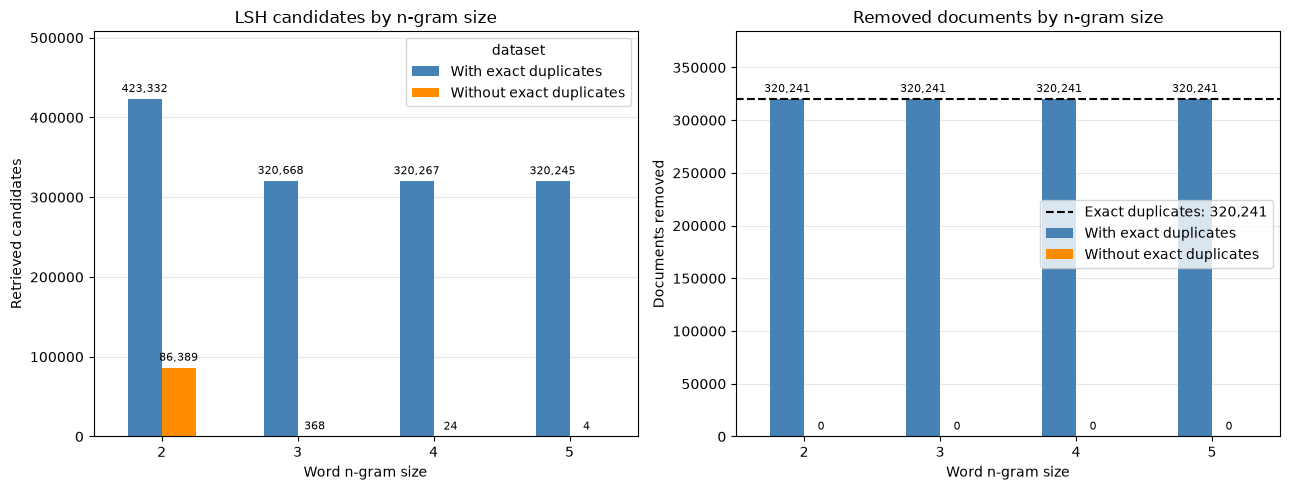

In [7]:
fig, axes = plt.subplots(1, 2, figsize=(13, 5))
for ax, metric, title, ylabel in [
    (axes[0], 'candidate_total', 'LSH candidates by n-gram size', 'Retrieved candidates'),
    (axes[1], 'removed_count', 'Removed documents by n-gram size', 'Documents removed'),
]:
    comparison = ngram_results_table.pivot(
        index='ngram_size', columns='dataset', values=metric,
    ).reindex(columns=list(ngram_result_dirs))
    comparison.plot.bar(ax=ax, color=['steelblue', 'darkorange'], rot=0)
    for bars in ax.containers:
        ax.bar_label(bars, fmt='{:,.0f}', padding=3, fontsize=8)
    ax.set_title(title)
    ax.set_xlabel('Word n-gram size')
    ax.set_ylabel(ylabel)
    ax.margins(y=0.2)
    ax.grid(axis='y', alpha=0.3)
    ax.set_axisbelow(True)
axes[1].axhline(
    exact_training_removed, color='black', linestyle='--',
    label=f'Exact duplicates: {exact_training_removed:,}',
)
axes[1].legend()
fig.tight_layout()
plt.show()


In [8]:
# Preview actual removals; retained indices refer to each experiment's input.
# Choose n-gram size 2, 3, 4, or 5.
preview_ngram = 2
preview_limit = 5
for label, directory in ngram_result_dirs.items():
    result = ngram_results_table.loc[
        (ngram_results_table['dataset'] == label)
        & (ngram_results_table['ngram_size'] == preview_ngram)
    ].iloc[0]
    print(f'{label}, {preview_ngram}-gram: {int(result.removed_count):,} removed')
    if result.removed_count == 0:
        continue
    input_name = 'normalized_train' if label == 'With exact duplicates' else 'exact_dedup_train'
    input_dataset = load_from_disk(str(artifacts_path / input_name))
    retained = pd.read_csv(directory / f'ngram_{preview_ngram}' / 'retained_indices.csv')
    retained_indices = set(retained.iloc[:, 0])
    from itertools import islice
    removed_indices = list(islice(
        (index for index in range(len(input_dataset)) if index not in retained_indices),
        preview_limit,
    ))
    removed_table = input_dataset.select(removed_indices).select_columns(['text']).to_pandas()
    removed_table.insert(0, 'Document index', removed_indices)
    display(removed_table.style.hide(axis='index').set_properties(
        **{'white-space': 'pre-wrap', 'text-align': 'left'},
    ).format(escape='html'))


With exact duplicates, 2-gram: 320,241 removed


Document index,text
39241,"Once upon a time, there was a little duck named Ducky. Ducky was very sad because he didn't have any friends to play with. One day, Ducky met a friendly frog named Froggy. ""Hi, Froggy! Will you be my friend?"" asked Ducky. ""Of course, I will be your friend, Ducky!"" replied Froggy. Froggy provided Ducky with a yellow flower to make him feel better. Ducky was so happy and thanked Froggy. They played together all day and had so much fun. When it was time to go home, Ducky said, ""Froggy, you are such a good friend. I am glad we met today."" Froggy smiled and said, ""You are my friend too, Ducky. Let's play again tomorrow!"" The sky turned gray, and Ducky went back to his nest feeling happy because he finally found a friend."
39242,"Once upon a time, there was a little boy named Timmy. Timmy loved going to the store with his mom. One day, he saw a toy that he really wanted. He asked his mom, ""Mommy, can I please have this toy?"" His mom looked at the price and said it was too expensive. Timmy was sad but understood. As they were walking around the store, Timmy saw something unusual. It was a big, pink elephant stuffed animal. He had never seen anything like it before. He asked his mom, ""Mommy, what is that unusual thing?"" His mom smiled and said it was a stuffed animal. Timmy thought it was silly but he still wanted the toy he saw earlier. When they got to the checkout, Timmy saw the toy he wanted again. He asked his mom, ""Mommy, can we please buy the toy now?"" His mom looked at the price again and said it was still too expensive. Timmy was disappointed but he knew there would be other toys he could ask for next time."
39243,"Once upon a time, there was a brave giraffe named Gigi. She loved to run and play with her friends in the jungle. One day, while playing hide and seek, she got her neck stuck in a tree branch. She cried for help, but no one could hear her. Days went by, and Gigi's neck started to hurt. She couldn't move or eat. Her friends searched everywhere for her, but they couldn't find her. Finally, a wise old owl found Gigi and called for help. A group of animals came to rescue Gigi. They worked together to restore her neck and get her free from the branch. Gigi was so happy to be reunited with her friends and able to run and play again. From that day on, she was always careful when playing near trees."
39244,"Once upon a time, there was a little girl named Lily. She loved going to the restaurant with her mommy and daddy. One day, they went to a new restaurant that was independent. Lily was excited to try something new. When they got there, Lily saw that the restaurant was very busy. She asked her mommy why there were so many people. Her mommy said, ""The restaurant is very popular, so the number of people who come here is increasing."" But when they got inside, they found out that they couldn't get a table. Lily was sad and started to cry. Her mommy asked the waiter if they could wait, but the waiter said it would take a long time. So, they decided to go to a different restaurant. Lily was happy again because she got to eat her favorite food."
39245,"Once upon a time, there was a happy family who lived in a big house. The family loved their country and were proud to be part of their nation. One day, they heard some bad news that made them sad. The news said that their country was in trouble and needed help. The family wanted to help, but they didn't know how. They decided to ask their neighbors for help. One neighbor said that they could donate some money to help their nation. Another neighbor said that they could volunteer their time to help. The family was glad that their neighbors wanted to help too. They realized that helping their nation was important and had a lot of value. In the end, the family and their neighbors worked together to help their nation. They were happy that they could make a difference and help their country. They knew that even though there may be problems, the

Without exact duplicates, 2-gram: 0 removed


#### Experiment 2: Vary similarity threshold

Run independently from the production pipeline:

```bash
python scripts/run_minhash_dedup_threshold_experiments.py --config configs/dataset_cycle.json
```

The script reuses saved signatures for the single n-gram size in `threshold_experiment.ngram_size`, varies the configured similarity thresholds, and keeps the LSH threshold fixed. No signatures are recomputed. The following cells load `threshold_results.csv` and plot the saved results. Missing optional results are skipped. Add `--overwrite` to rerun completed experiments.


In [9]:
# Load the saved threshold sweep; no deduplication is rerun.
threshold_results_path = (
    artifacts_path / 'experiment_exact_and_minhash'
    / 'minhash_similarity_threshold_results' / 'threshold_results.csv'
)
threshold_results_table = None
if threshold_results_path.is_file():
    threshold_results_table = (
        pd.read_csv(threshold_results_path)
        .query('ngram_size == 2')
        .sort_values('similarity_threshold')
        .reset_index(drop=True)
    )
    if threshold_results_table.empty:
        print('No 2-gram results found in', threshold_results_path)
    else:
        display(threshold_results_table)
else:
    print('Missing saved threshold results:', threshold_results_path)


,experiment_id,ngram_size,similarity_threshold,lsh_threshold,num_perm,seed,scheme,total_documents,retained_count,removed_count,removed_percentage,candidate_total,runtime_seconds,retained_indices_path
0,threshold_0.1,2,0.10,0.6,128,1,affine32,1799248,1784112,15136,0.841240,21074,2701.823248,artifacts/dataset_cycle/experiment_exact_and_m...
1,threshold_0.25,2,0.25,0.6,128,1,affine32,1799248,1798540,708,0.039350,82596,561.642111,artifacts/dataset_cycle/experiment_exact_and_m...
2,threshold_0.5,2,0.50,0.6,128,1,affine32,1799248,1799245,3,0.000167,86389,564.348753,artifacts/dataset_cycle/experiment_exact_and_m...
3,threshold_0.75,2,0.75,0.6,128,1,affine32,1799248,1799248,0,0.000000,86389,563.967266,artifacts/dataset_cycle/experiment_exact_and_m...
4,threshold_0.8,2,0.80,0.6,128,1,affine32,1799248,1799248,0,0.000000,86389,556.870536,artifacts/dataset_cycle/experiment_exact_and_m...
5,threshold_0.9,2,0.90,0.6,128,1,affine32,1799248,1799248,0,0.000000,86389,565.383056,artifacts/dataset_cycle/experiment_exact_and_m...


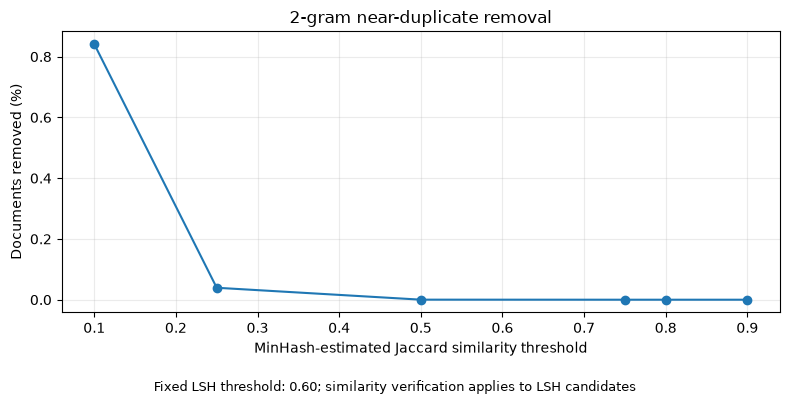

In [10]:
if threshold_results_table is not None and not threshold_results_table.empty:
    results = threshold_results_table
    if results['lsh_threshold'].nunique() != 1:
        raise ValueError('Select results with a single fixed LSH threshold before plotting.')

    fig, ax = plt.subplots(figsize=(8, 4))
    ax.plot(
        results['similarity_threshold'],
        results['removed_percentage'],
        marker='o',
    )
    ax.set(
        xlabel='MinHash-estimated Jaccard similarity threshold',
        ylabel='Documents removed (%)',
        title='2-gram near-duplicate removal',
    )
    ax.grid(alpha=0.25)
    fig.text(
        0.5, 0.01,
        f"Fixed LSH threshold: {results.iloc[0]['lsh_threshold']:.2f}; "
        'similarity verification applies to LSH candidates',
        ha='center', fontsize=9,
    )
    fig.tight_layout(rect=(0, 0.06, 1, 1))
    plt.show()


In [12]:
# Production data uses the selected configuration, independently of demonstrations.
# Run: python scripts/run_minhash_deduplication.py --config configs/dataset_cycle.json
from datasets import load_from_disk

production_outputs = ['minhash_dedup_train', 'minhash_dedup_validation', 'minhash_dedup_metrics.csv']
if any(not (artifacts_path / name).exists() for name in production_outputs):
    raise FileNotFoundError(
        'Run: python scripts/run_minhash_deduplication.py --config configs/dataset_cycle.json'
    )
stories_train_dataset = load_from_disk(str(artifacts_path / 'minhash_dedup_train'))
stories_valid_dataset = load_from_disk(str(artifacts_path / 'minhash_dedup_validation'))


FileNotFoundError: Run: python scripts/run_minhash_deduplication.py --config configs/dataset_cycle.json

In [ ]:
minhash_dedup_metrics = pd.read_csv(artifacts_path / 'minhash_dedup_metrics.csv')
display(minhash_dedup_metrics)
for row in minhash_dedup_metrics.itertuples(index=False):
    _LOGGER.info(
        '%s: %d -> %d documents (%.2f%% removed by MinHash)',
        row.split, row.before, row.after, row.removed_percentage,
    )


In [ ]:
# Both splits are now loaded after production MinHash deduplication.
# Continue with final tokenization below.




<div style="max-width: 850px;">

### Step 4 - Tokenization

---

A dataset consist of documents. However, dataset is usually regarded as amount of tokens it cointains. Even more, when training a model we usually refer to the total count of tokens the model saw during training considering epochs too - e.g. GPT4 was trained on XX tokens. GPT models use a **Byte-Pair Encoding (BPE)** tokenizers, which decompose words into sub-words based on the most frequent pair of characters in subwords.

As an example, consider the input dataset `'low', 'lower', 'lowest'`. BPE works as follows

1. **Initialize vocabulary** - start with all unique characters as tokens including a token for unknown:

Vocabulary: `'l', 'o', 'w', 'e', 'r', 's', 't', '<unk>'`

2. **Count token pairs in the dataset**

```
(l,o) = 3    (w,e) = 2   (e,s) = 1
(o,w) = 3   (e,r) = 2   (s,t) = 1
```

3. **Merge most frequent pair into new subword token**:

Vocabulary after merging `(l,o)`: `'lo', 'w', 'e', 'r', 's', 't', '<unk>'`

4. **Repeat the process until desired granularity**:

Final vocabulary : `'low', 'lower', 'est', '<unk>'`

5. **The dictionary of vocabulary comprise of**:

`{'low':0, 'lower':1, 'est':3, '<unk>':3}`


We will apply a BPE tokenizer to our training and validation data. Specifically, we will use the tokenizer used for GPT2 models. Later we will compare the statisctics from the clean data w.r.t. the raw dataset.

</div>


In [ ]:

def preprocess_tokenizer_update(batch):
    return {'tokenized': tokenizer(batch['text'])['input_ids']}


_LOGGER.info('Tokenizing training dataset')
stories_train_dataset = stories_train_dataset.map(
    preprocess_tokenizer_update,
    batched=True,
    batch_size=tokenization_batch_size,
    num_proc=num_proc,
    desc='Tokenizing train data'
)

_LOGGER.info('Tokenizing validation dataset')
stories_valid_dataset = stories_valid_dataset.map(
    preprocess_tokenizer_update,
    batched=True,
    batch_size=tokenization_batch_size,
    num_proc=num_proc,
    desc='Tokenizing val data'
)

print('Done!')

## Save prepared data

Continue with scoring and filtering in [perplexity_filtering.ipynb](perplexity_filtering.ipynb).


In [ ]:
# Save after normalization, deduplication, and GPT-2 tokenization.
data_path.mkdir(parents=True, exist_ok=True)
stories_train_dataset.save_to_disk(data_path / 'tinystories_prepared_train')
stories_valid_dataset.save_to_disk(data_path / 'tinystories_prepared_validation')